<a href="https://colab.research.google.com/github/HamzaEric/aapl_volatility_modelling/blob/main/Notebooks/financial_time_series.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
from yf_loader import get_daily_data
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df_aapl = get_daily_data('AAPL')
df_nvda = get_daily_data('NVDA')

In [3]:
df_aapl.head()

,open,high,low,close,volume
date,,,,,
1980-12-12,0.098122,0.098549,0.098122,0.098122,469033600
1980-12-15,0.093430,0.093430,0.093003,0.093003,175884800
1980-12-16,0.086604,0.086604,0.086177,0.086177,105728000
1980-12-17,0.088310,0.088737,0.088310,0.088310,86441600
1980-12-18,0.090870,0.091297,0.090870,0.090870,73449600


In [4]:
df_nvda.head()

,open,high,low,close,volume
date,,,,,
1999-01-22,0.040018,0.044663,0.035492,0.037517,2714688000
1999-01-25,0.040494,0.041923,0.037517,0.041448,510480000
1999-01-26,0.041923,0.042757,0.037636,0.038231,343200000
1999-01-27,0.038350,0.039303,0.036206,0.038113,244368000
1999-01-28,0.038113,0.038350,0.037755,0.037993,227520000


In [6]:
df_aapl.to_csv('/content/drive/MyDrive/aapl.csv')
df_nvda.to_csv('/content/drive/MyDrive/nvda.csv')

In [9]:
df = pd.read_csv('/content/drive/MyDrive/aapl.csv',index_col="date", parse_dates=["date"])
df.index = pd.to_datetime(df.index)

print(df.shape)
print(df.info())
print(df.dtypes)

(11569, 5)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 11569 entries, 1980-12-12 to 2026-11-06
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    11569 non-null  float64
 1   high    11569 non-null  float64
 2   low     11569 non-null  float64
 3   close   11569 non-null  float64
 4   volume  11569 non-null  int64  
dtypes: float64(4), int64(1)
memory usage: 542.3 KB
None
open      float64
high      float64
low       float64
close     float64
volume      int64
dtype: object


In [10]:
df.index.sort_values(ascending=True)

DatetimeIndex(['1980-12-12', '1980-12-15', '1980-12-16', '1980-12-17',
               '1980-12-18', '1980-12-19', '1980-12-22', '1980-12-23',
               '1980-12-24', '1980-12-26',
               ...
               '2026-10-26', '2026-10-27', '2026-10-28', '2026-10-29',
               '2026-10-30', '2026-11-02', '2026-11-03', '2026-11-04',
               '2026-11-05', '2026-11-06'],
              dtype='datetime64[ns]', name='date', length=11569, freq=None)

# Computing Returns

Raw prices are non-stationary and cannot be fed directly into volatility models. You need to turn the closing-price series into a return series.

The GARCH models expect log returns (continuously compounded) because they are additive over time and approximately normal for small daily changes.

In [11]:
close = df['close']

close.head()

,close
date,
1980-12-12,0.098122
1980-12-15,0.093003
1980-12-16,0.086177
1980-12-17,0.088310
1980-12-18,0.090870


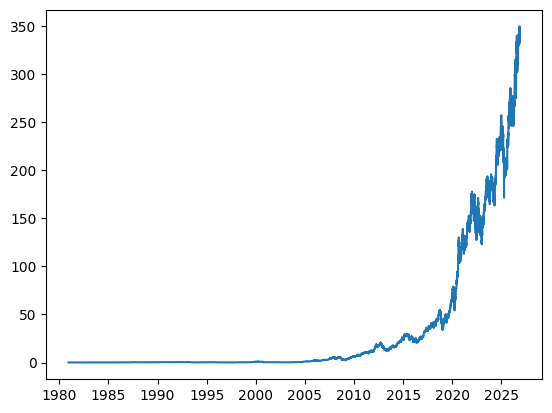

In [12]:
plt.plot(close)

# Log Returns


In [14]:
log_returns = np.log(close / close.shift(1)).dropna()
log_returns.name = "log_return"

print("log_returns shape:", log_returns.shape)
print(log_returns.head())

log_returns shape: (11568,)
date
1980-12-15   -0.053581
1980-12-16   -0.076231
1980-12-17    0.024449
1980-12-18    0.028580
1980-12-19    0.059239
Name: log_return, dtype: float64


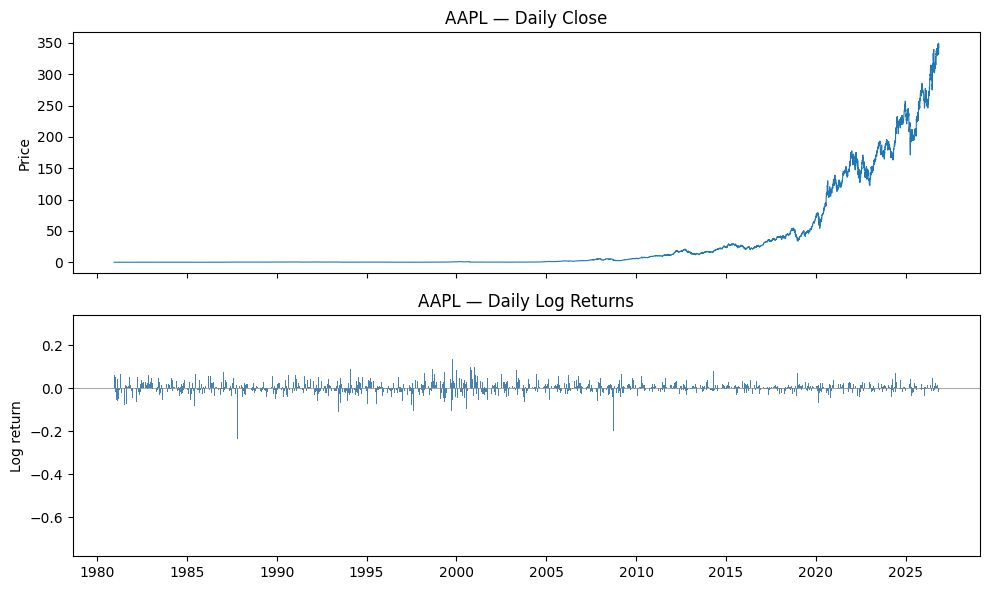

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(close, linewidth=0.8)
axes[0].set_ylabel("Price")
axes[0].set_title("AAPL — Daily Close")

axes[1].bar(
    log_returns.index,
    log_returns.values,
    width=2,
    color="steelblue",
)
axes[1].set_ylabel("Log return")
axes[1].set_title("AAPL — Daily Log Returns")
axes[1].axhline(0, color="gray", linewidth=0.5)

plt.tight_layout()
plt.show()

# Returns Statistics

Before modeling, quantify the basic properties of the return series.
Mean, standard deviation, **skewness**, and **kurtosis** tell you whether
the data is roughly symmetric and how heavy the tails are. Financial
returns famously have **excess kurtosis** — heavier tails than a normal
distribution — which further motivates GARCH-type models.

In [16]:
log_returns.describe()

,log_return
count,11568.000000
mean,0.000705
std,0.027880
min,-0.731248
25%,-0.012395
50%,0.000047
75%,0.014006
max,0.286892


A kurtosis above zero
means heavier tails than a normal distribution.


In [18]:
# Compute skewness
skew = log_returns.skew()

# Compute kurtosis

kurt = log_returns.kurt()

print(f"Skewness: {skew:.4f}")
print(f"Kurtosis: {kurt:.4f}")

Skewness: -1.7337
Kurtosis: 48.3729


> - **Skewness** near 0 ⇒ roughly symmetric returns; negative skew
>   (common in equities) ⇒ crashes are sharper than rallies.
> - **Excess kurtosis > 0** ⇒ **fat tails**: extreme days happen far more
>   often than a normal distribution predicts. This is *why* a Gaussian
>   constant-variance model under-states risk — and a recurring theme
>   into Lesson 3.

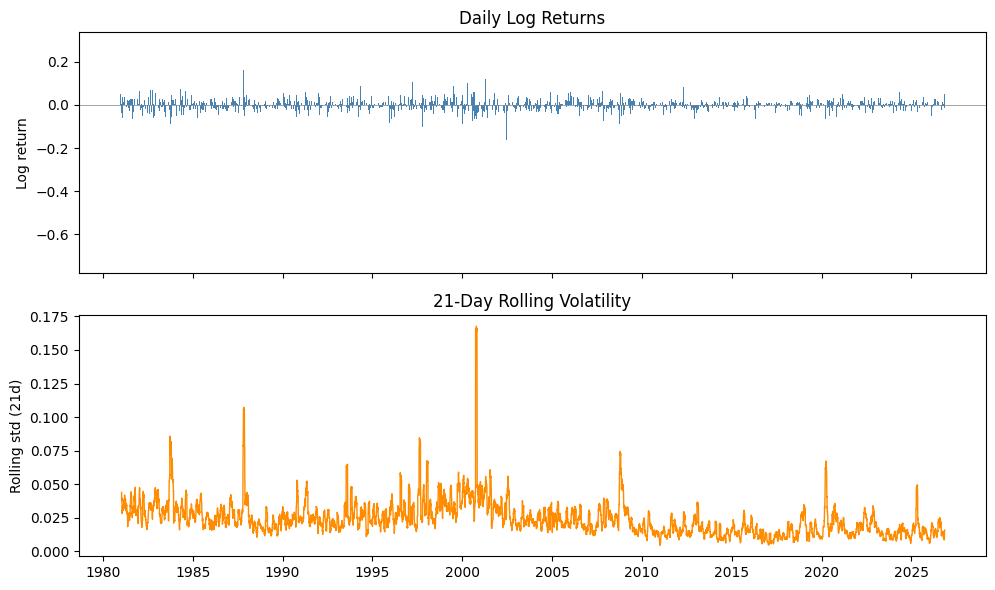

In [19]:
rolling_vol = log_returns.rolling(21).std()
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].bar(
    log_returns.index,
    log_returns.values,
    width=2,
    color="steelblue",
)
axes[0].set_ylabel("Log return")
axes[0].set_title("Daily Log Returns")
axes[0].axhline(0, color="gray", linewidth=0.5)
axes[1].plot(rolling_vol, color="darkorange", linewidth=1)
axes[1].set_ylabel("Rolling std (21d)")
axes[1].set_title("21-Day Rolling Volatility")
plt.tight_layout()
plt.show()

The bottom panel is a *direct picture of volatility over time*. Where
> it rises, returns are swinging widely; where it dips, the market is
> calm. A constant-variance model would replace this whole wandering line
> with one flat level — clearly a poor fit.